In this notebook I will try to do a linear reconstruction of a weak phase object.

In [ ]:
import sys
sys.path.append("../src/focalseriesrecon")

import numpy as np

from utils import *
from optics import *
from specimen import *
from reconstruction import *

Make the phase object:

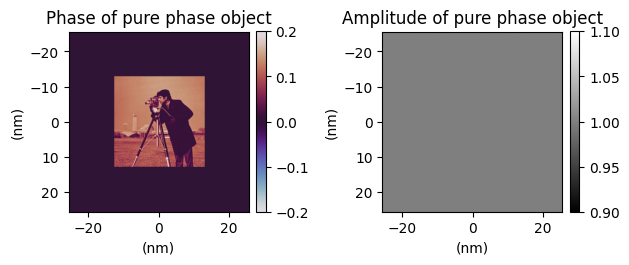

In [2]:
spec = Specimen(phase_source='../images/cameraman512.jpg', phase_strength=0.2, resize_img=512, pixel_size=0.05)

fig, ax1 = plt.subplots(1, 2)
plot_2d(spec.owf, x=spec.x, y=spec.y, mode="phase", title="Phase of pure phase object", vmin = -0.2, vmax = 0.2, xlabel="(nm)", ylabel="(nm)", ax=ax1[0])
plot_2d(spec.owf, x=spec.x, y=spec.y, mode="abs", title="Amplitude of pure phase object", xlabel="(nm)", ylabel="(nm)", ax=ax1[1])
plt.tight_layout()

Generate a focal series and the corresponding filter functions:

(<Figure size 1000x750 with 12 Axes>,
 array([<Axes: title={'center': 'Δf = -20nm'}>,
        <Axes: title={'center': 'Δf = -9nm'}>,
        <Axes: title={'center': 'Δf = 2nm'}>,
        <Axes: title={'center': 'Δf = 13nm'}>,
        <Axes: title={'center': 'Δf = 24nm'}>,
        <Axes: title={'center': 'Δf = 35nm'}>,
        <Axes: title={'center': 'Δf = 45nm'}>,
        <Axes: title={'center': 'Δf = 56nm'}>,
        <Axes: title={'center': 'Δf = 67nm'}>,
        <Axes: title={'center': 'Δf = 78nm'}>,
        <Axes: title={'center': 'Δf = 89nm'}>,
        <Axes: title={'center': 'Δf = 100nm'}>], dtype=object))

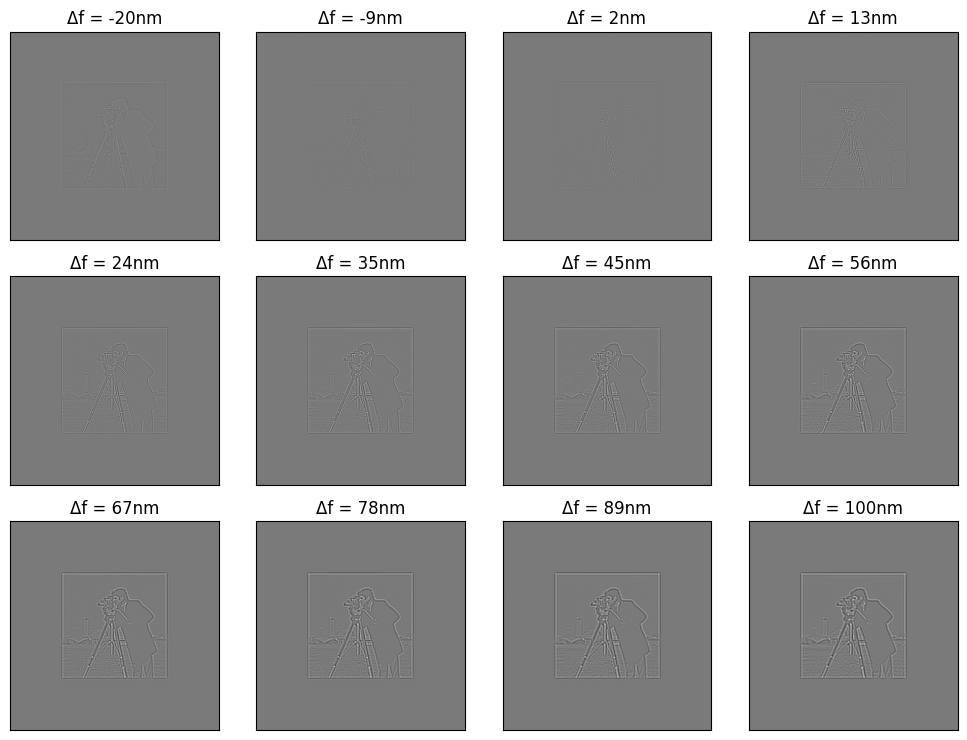

In [ ]:
acc_voltage = 300
wavelength = electron_wavelength(acc_voltage)
cs = 1.2e6
aperture_alpha_max = 13
defoci = np.linspace(-20, 100, 12)
dose_per_pixel = 1000

focal_series = focal_series_nonlinear(defoci, spec.owf, spec.k_grid, wavelength, cs, aperture_alpha_max)
focal_series_noisy = poisson_noise(focal_series, dose_per_pixel)
plot_focal_series(focal_series_noisy, defoci)


We can now apply the filter functions on the defocus series to reconstruct the phase object.

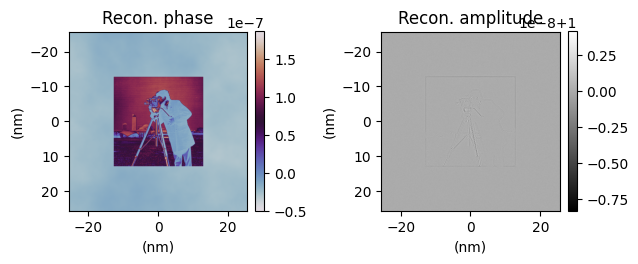

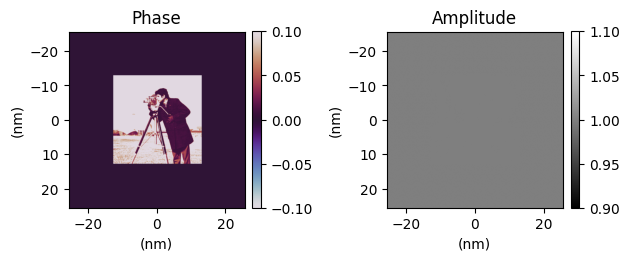

In [ ]:
reconstructed_owf = linear_reconstruction(focal_series_noisy, defoci, spec.k_grid, wavelength, cs, aperture_alpha_max)

fig, ax4 = plt.subplots(1, 2)
plot_2d(reconstructed_owf, x=spec.x, y=spec.y, mode="phase", title="Recon. phase", xlabel="(nm)", ylabel="(nm)", ax=ax4[0])
plot_2d(reconstructed_owf, x=spec.x, y=spec.y, mode="abs", title="Recon. amplitude", xlabel="(nm)", ylabel="(nm)", ax=ax4[1])
plt.tight_layout()

fig, ax5 = plt.subplots(1, 2)
plot_2d(spec.owf, x=spec.x, y=spec.y, mode="phase", title="Phase", xlabel="(nm)", ylabel="(nm)", vmin=-0.1, vmax=0.1, ax=ax5[0])
plot_2d(spec.owf, x=spec.x, y=spec.y, mode="abs", title="Amplitude", xlabel="(nm)", ylabel="(nm)", vmin=0.9, vmax=1.1, ax=ax5[1])
plt.tight_layout()

We can test how good the reconstructed image is for a series of doses:

In [ ]:
def reconstruct_image(spec, defoci, wavelength, cs, alpha_max, dose_per_pixel):
    focal_series = focal_series_nonlinear(defoci, spec.owf, spec.k_grid, wavelength, cs, aperture_alpha_max)
    focal_series_noisy = poisson_noise(focal_series, dose_per_pixel)
    reconstructed_owf = linear_reconstruction(focal_series_noisy, defoci, spec.k_grid, wavelength, cs, aperture_alpha_max)

    fig, ax = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained")
    plot_2d(reconstructed_owf, x=spec.x, y=spec.y, mode="phase", title=f"Recon. phase", xlabel="(nm)", ylabel="(nm)", ax=ax[0])
    plot_2d(reconstructed_owf, x=spec.x, y=spec.y, mode="abs", title="Recon. amplitude", xlabel="(nm)", ylabel="(nm)", ax=ax[1])
    fig.suptitle(f"Dose: {dose_per_pixel} electrons per pixel")

doses = [10 ** i for i in range (1, 12)]
for dose in doses:
    reconstruct_image(spec, defoci, wavelength, cs, aperture_alpha_max, dose)
    